# Чекпойнт 2. Разведочный анализ данных

**Проект:** прогнозирование котировок криптовалют на основе временных рядов и тональности новостей.

**Постановка.** Дневной прогноз BTC/USDT и ETH/USDT на один день вперёд. Основная целевая переменная — лог-доходность следующего дня, дополнительная — её направление. Выбор доходности вместо цены обоснован в разделах 5.3 и 8.

**Данные** (загружаются скриптом `src/load_data.py`, снимок от 10 ноября 2026 года):

| Источник | Что берём | Период |
|---|---|---|
| Binance | дневные свечи BTCUSDT и ETHUSDT: OHLC, объёмы, число сделок, объём покупок тейкеров | 17.08.2017 — 09.11.2026 |
| alternative.me | Crypto Fear & Greed Index | с 01.02.2018 |
| Yahoo Finance | S&P 500 (`^GSPC`), индекс доллара DXY (`DX-Y.NYB`) | с 17.08.2017 |

Новостные признаки по плану проекта появятся на ЧП 5, здесь анализируются только рыночные ряды и внешние факторы. Итоговые выводы собраны в разделе 9.

## 0. Подготовка окружения

In [1]:
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from arch import arch_model
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from pandas.tseries.holiday import (
    AbstractHolidayCalendar, GoodFriday, Holiday, USLaborDay, USMartinLutherKingJr,
    USMemorialDay, USPresidentsDay, USThanksgivingDay, nearest_workday, sunday_to_monday,
)
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, coint, kpss

warnings.filterwarnings("ignore", category=InterpolationWarning)
warnings.filterwarnings("ignore", message=".*currently returns a plain tuple.*")

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, SURFACE, GRID = "#23231f", "#6b6a63", "#fcfcfb", "#e7e6e1"
ASSET_COLORS = {"BTC": BLUE, "ETH": ORANGE}
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "legend.frameon": False, "lines.linewidth": 1.3, "font.size": 9.5,
})
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_rows", 120,
              "display.float_format", lambda v: f"{v:,.4f}")

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW = ROOT / "data" / "raw"


def read(name):
    return pd.read_csv(RAW / f"{name}.csv", parse_dates=["date"]).set_index("date")


btc, eth, fng, sp500, dxy = (read(n) for n in ["btcusdt_1d", "ethusdt_1d", "fear_greed", "sp500", "dxy"])
ASSETS = {"BTC": btc, "ETH": eth}
SOURCES = {"BTC": btc, "ETH": eth, "Fear & Greed": fng, "S&P 500": sp500, "DXY": dxy}
pd.DataFrame({name: {"строк": len(df), "столбцов": df.shape[1], "начало": df.index.min().date(),
                     "конец": df.index.max().date()} for name, df in SOURCES.items()}).T

,строк,столбцов,начало,конец
BTC,3372,9,2017-08-17,2026-11-09
ETH,3372,9,2017-08-17,2026-11-09
Fear & Greed,3201,2,2018-02-01,2026-11-10
S&P 500,2320,1,2017-08-17,2026-11-09
DXY,2808,1,2017-08-17,2026-11-10


## 1. Основные статистики

In [2]:
for name, df in SOURCES.items():
    print(name)
    display(df.reset_index(drop=True).describe(include="all").T)

BTC


,count,mean,std,min,25%,50%,75%,max
open,"3,372.0000","39,454.7219","32,627.5961","3,188.0100","9,516.3950","29,312.9150","63,731.9725","124,658.5400"
high,"3,372.0000","40,258.5085","33,130.7702","3,276.5000","9,723.0000","29,888.3200","64,689.2075","126,199.6300"
low,"3,372.0000","38,588.7323","32,089.6199","2,817.0000","9,242.9025","28,878.6750","62,500.4700","123,084.0000"
close,"3,372.0000","39,475.8509","32,627.8133","3,189.0200","9,517.8100","29,322.9150","63,759.3975","124,658.5400"
volume,"3,372.0000","58,352.7481","74,413.3642",228.1081,"21,329.3517","36,424.0995","61,640.6906","760,705.3628"
quote_volume,"3,372.0000","1,723,284,027.8555","1,860,056,373.4352","977,865.7333","422,439,752.5265","1,190,734,774.5561","2,309,383,255.4805","17,465,307,097.8841"
taker_buy_base,"3,372.0000","28,976.0946","37,040.9844",56.1901,"10,609.4154","18,199.2956","30,509.5404","374,775.5741"
taker_buy_quote,"3,372.0000","850,913,940.9998","923,696,155.5745","241,363.8005","209,391,443.3522","582,960,657.3262","1,139,231,904.4546","8,783,916,247.6761"
trades,"3,372.0000","2,026,640.0976","2,227,297.3011","2,153.0000","471,063.7500","1,254,675.0000","2,696,173.5000","15,364,010.0000"


ETH


,count,mean,std,min,25%,50%,75%,max
open,"3,372.0000","1,699.8858","1,254.1976",83.7500,365.3850,"1,750.1450","2,607.4850","4,832.0700"
high,"3,372.0000","1,747.5836","1,286.6268",85.0000,377.6000,"1,802.9350","2,679.9100","4,956.7800"
low,"3,372.0000","1,647.0270","1,218.0454",81.7900,351.2975,"1,703.7500","2,523.6275","4,713.8900"
close,"3,372.0000","1,700.4295","1,253.9983",83.7600,366.1900,"1,751.0650","2,607.4775","4,832.0700"
volume,"3,372.0000","512,467.3853","436,639.3246","1,060.5673","236,317.4450","405,334.9351","656,376.4334","4,663,239.9286"
quote_volume,"3,372.0000","880,102,333.1561","975,298,716.6943","302,739.7338","120,140,490.6272","602,729,377.3136","1,315,111,766.6131","11,641,524,166.9875"
taker_buy_base,"3,372.0000","255,441.5298","216,858.8422",566.6464,"117,850.3829","200,377.6491","330,001.7824","2,314,458.3700"
taker_buy_quote,"3,372.0000","437,270,596.3948","483,315,882.0226","156,157.9955","60,552,004.9424","297,820,916.0091","655,778,190.8549","5,659,752,851.7779"
trades,"3,372.0000","1,333,568.2370","1,749,738.0227","1,431.0000","200,200.2500","703,799.5000","1,636,515.0000","13,667,587.0000"


Fear & Greed


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
fng_value,"3,201.0000",NaN,NaN,NaN,45.7391,21.9916,5.0000,26.0000,44.0000,65.0000,95.0000
fng_class,3201,5,Fear,919,NaN,NaN,NaN,NaN,NaN,NaN,NaN


S&P 500


,count,mean,std,min,25%,50%,75%,max
sp500_close,"2,320.0000","4,373.4593","1,475.9231","2,237.3999","2,991.4300","4,138.0552","5,432.1351","7,818.9302"


DXY


,count,mean,std,min,25%,50%,75%,max
dxy_close,"2,323.0000",98.8036,5.1152,88.5900,94.9700,98.3500,102.7800,114.1100


**Что видно из статистик.** Масштаб рядов менялся на порядки: BTC закрывался в диапазоне от 3 189 до 124 659 USDT, ETH — от 84 до 4 832 USDT. Среднее цены BTC (39 476) заметно выше медианы (29 323), распределение уровней сильно скошено вправо, поэтому моделировать уровень цены напрямую неудобно. Объёмы также различаются на несколько порядков, для них нужен логарифм. Единственный категориальный признак — класс Fear & Greed (5 значений, чаще всего Fear: 919 дней). Значения индекса лежат в диапазоне 5–95, S&P 500 и DXY — в ожидаемых диапазонах.

## 2. Пропущенные значения

### 2.1. Пропуски в исходных файлах и дыры в календаре

In [3]:
rows = []
for name, df in SOURCES.items():
    calendar = pd.date_range(df.index.min(), df.index.max())
    absent = calendar.difference(df.index)
    empty = df.index[df.isna().any(axis=1)]
    rows.append({
        "источник": name, "строк": len(df), "дней в календаре": len(calendar),
        "нет строки": len(absent), "строка есть, значение NaN": len(empty),
        "доля пропущенных дней": (len(absent) + len(empty)) / len(calendar),
        "из них Сб/Вс": absent.union(empty).day_of_week.isin([5, 6]).mean() if len(absent) + len(empty) else np.nan,
    })
pd.DataFrame(rows).set_index("источник")

,строк,дней в календаре,нет строки,"строка есть, значение NaN",доля пропущенных дней,из них Сб/Вс
источник,,,,,,
BTC,3372,3372,0,0,0.0000,NaN
ETH,3372,3372,0,0,0.0000,NaN
Fear & Greed,3201,3205,4,0,0.0012,0.7500
S&P 500,2320,3372,1052,0,0.3120,0.9163
DXY,2808,3373,565,485,0.3113,0.9181


### 2.2. Что означают пропуски: проверка гипотез

**Гипотеза.** Пропуски в S&P 500 и DXY означают не потерю данных, а нерабочие дни бирж. Для S&P 500 проверим, совпадают ли пропущенные будни с календарём праздников NYSE. Для DXY посмотрим, на какие дни недели приходятся значения NaN.

In [4]:
class NyseCalendar(AbstractHolidayCalendar):
    rules = [
        Holiday("New Year", month=1, day=1, observance=sunday_to_monday),
        USMartinLutherKingJr, USPresidentsDay, GoodFriday, USMemorialDay,
        Holiday("Juneteenth", month=6, day=19, start_date="2022-01-01", observance=nearest_workday),
        Holiday("Independence", month=7, day=4, observance=nearest_workday),
        USLaborDay, USThanksgivingDay,
        Holiday("Christmas", month=12, day=25, observance=nearest_workday),
    ]


calendar = pd.date_range(sp500.index.min(), sp500.index.max())
absent = calendar.difference(sp500.index)
weekday_gaps = absent[absent.day_of_week < 5]
special_closures = pd.to_datetime(["2018-12-05", "2025-01-09"])  # дни национального траура
holidays = NyseCalendar().holidays(calendar.min(), calendar.max()).union(special_closures)
unexplained = weekday_gaps.difference(holidays)
not_absent = holidays[holidays.day_of_week < 5].difference(absent)

print(f"S&P 500: пропущено дней {len(absent)}, из них выходных {len(absent) - len(weekday_gaps)}, будней {len(weekday_gaps)}")
print(f"Будни, объяснённые календарём NYSE: {len(weekday_gaps) - len(unexplained)} из {len(weekday_gaps)}")
print("Необъяснённые будни:", list(unexplained.strftime("%Y-%m-%d")))
print("Праздники, в которые данные всё же есть:", list(not_absent.strftime("%Y-%m-%d")))

dxy_nan = dxy.index[dxy["dxy_close"].isna()]
dow_names = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
print("\nDXY, значения NaN по дням недели:",
      {dow_names[k]: int(v) for k, v in pd.Series(dxy_nan.day_of_week).value_counts().sort_index().items()})
print("DXY, будни с NaN:", list(dxy_nan[dxy_nan.day_of_week < 5].strftime("%Y-%m-%d")))
print("Fear & Greed, дни без значения:", list(pd.date_range(fng.index.min(), fng.index.max()).difference(fng.index).strftime("%Y-%m-%d")))

S&P 500: пропущено дней 1052, из них выходных 964, будней 88
Будни, объяснённые календарём NYSE: 88 из 88
Необъяснённые будни: []
Праздники, в которые данные всё же есть: []

DXY, значения NaN по дням недели: {'Чт': 2, 'Пт': 1, 'Вс': 482}
DXY, будни с NaN: ['2023-11-23', '2025-06-19', '2025-07-04']
Fear & Greed, дни без значения: ['2018-04-14', '2018-04-15', '2018-04-16', '2024-10-26']


**Результат проверки гипотезы.** Гипотеза подтвердилась:

- **S&P 500:** из 1 052 пропущенных дней 964 приходятся на выходные, а все 88 пропущенных будней совпали с праздниками NYSE и днями национального траура. Необъяснённых пропусков нет.
- **DXY:** 482 из 485 значений NaN приходятся на воскресенья (Yahoo отдаёт пустую строку перед началом торговой недели). Остальные три — американские праздники: 23.11.2023 (День благодарения), 19.06.2025 (Juneteenth) и 04.07.2025.
- **Fear & Greed:** 168 дней до запуска индекса 1 февраля 2018 года и 4 случайных разрыва (14–16 апреля 2018 и 26 октября 2024). Это сбои публикации, связи с календарём нет.

Таким образом, пропуски в макрорядах означают «рынок закрыт», то есть новой информации нет. Значения не потеряны и не зависят от самой целевой переменной.

### 2.3. Сводная таблица и обработка пропусков

Общая разреженность объединённой таблицы: 13.49%


,пропусков,доля
btc_close,0,0.0000
eth_close,0,0.0000
fng_value,172,0.0510
sp500_close,1052,0.3120
dxy_close,1050,0.3114


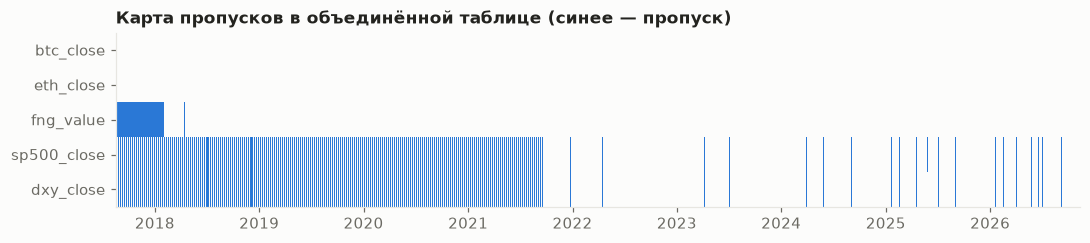

После обработки и обрезки по старту Fear & Greed: (3204, 5) | пропусков: 0
Доля нулевых дневных изменений S&P 500 после заполнения: 31.2%


In [5]:
base = pd.DataFrame(index=btc.index)
base["btc_close"], base["eth_close"] = btc["close"], eth["close"]
base["fng_value"] = fng["fng_value"].reindex(base.index)
base["sp500_close"] = sp500["sp500_close"].reindex(base.index)
base["dxy_close"] = dxy["dxy_close"].reindex(base.index)

summary = pd.DataFrame({"пропусков": base.isna().sum(), "доля": base.isna().mean()})
print(f"Общая разреженность объединённой таблицы: {base.isna().to_numpy().mean():.2%}")
display(summary)

fig, ax = plt.subplots(figsize=(10, 2.3))
ax.imshow(base.isna().T.to_numpy(), aspect="auto", interpolation="nearest",
          cmap=LinearSegmentedColormap.from_list("gaps", [SURFACE, BLUE]),
          extent=[0, len(base), len(base.columns), 0])
ax.set_yticks(np.arange(len(base.columns)) + 0.5, base.columns)
ticks = [base.index.get_indexer([pd.Timestamp(f"{y}-01-01")])[0] for y in range(2018, 2027)]
ax.set_xticks(ticks, range(2018, 2027))
ax.grid(False)
ax.set_title("Карта пропусков в объединённой таблице (синее — пропуск)")
plt.tight_layout()
plt.show()

clean = base.copy()
clean["sp500_close"] = clean["sp500_close"].ffill()
clean["dxy_close"] = clean["dxy_close"].ffill()
clean["fng_value"] = clean["fng_value"].ffill(limit=3)
clean = clean.loc["2018-02-01":]
print("После обработки и обрезки по старту Fear & Greed:", clean.shape, "| пропусков:", int(clean.isna().sum().sum()))
print(f"Доля нулевых дневных изменений S&P 500 после заполнения: {(clean['sp500_close'].diff() == 0).mean():.1%}")

**Обработка пропусков.** Котировки BTC и ETH полны (0 пропусков, календарь непрерывен). Общая разреженность объединённой таблицы 13.5% почти полностью объясняется нерабочими днями бирж (S&P 500 — 31.2%, DXY — 31.1% дней) и поздним стартом Fear & Greed (5.1%).

- **S&P 500 и DXY: заполнение последним известным значением.** Крипторынок торгуется круглосуточно, и в выходной лучшая оценка уровня закрытого рынка — его последнее закрытие. Заглядывания в будущее такой способ не создаёт. Следствие: в 31.2% дней доходность S&P 500 равна нулю, а понедельничная включает все выходные. Интерполяцией пользоваться нельзя: она использует будущие значения.
- **Fear & Greed: заполнение не более чем на 3 дня** (этого достаточно для самого длинного разрыва). Период до запуска индекса отбрасывается: восстанавливать несуществующие значения некорректно.
- **Рабочая выборка** начинается с 1 февраля 2018 года и не содержит пропусков. При этом 168 первых дней истории BTC и ETH остаются в анализе отдельных рядов.

## 3. Ошибочные значения

In [6]:
def price_checks(df):
    vwap = df["quote_volume"] / df["volume"]
    return {
        "дубликаты дат": int(df.index.duplicated().sum()),
        "неположительные цены": int((df[["open", "high", "low", "close"]] <= 0).sum().sum()),
        "нулевой/отрицательный объём": int((df["volume"] <= 0).sum()),
        "high < max(open, close, low)": int((df["high"] < df[["open", "close", "low"]].max(axis=1)).sum()),
        "low > min(open, close, high)": int((df["low"] > df[["open", "close", "high"]].min(axis=1)).sum()),
        "taker_buy > volume": int((df["taker_buy_base"] > df["volume"]).sum()),
        "VWAP вне [low, high]": int(((vwap < df["low"]) | (vwap > df["high"])).sum()),
        "open отличается от прошлого close > 1%": int((abs(df["open"] / df["close"].shift() - 1) > 0.01).sum()),
    }


display(pd.DataFrame({name: price_checks(df) for name, df in ASSETS.items()}))
gap = abs(eth["open"] / eth["close"].shift() - 1) > 0.01
display(eth.loc[gap, ["open", "close", "volume", "trades"]].assign(prev_close=eth["close"].shift()[gap]))
print("Fear & Greed вне диапазона [0, 100]:", int((~fng["fng_value"].between(0, 100)).sum()))
display(fng.groupby("fng_class")["fng_value"].agg(["min", "max", "count"]).sort_values("min"))

,BTC,ETH
дубликаты дат,0,0
неположительные цены,0,0
нулевой/отрицательный объём,0,0
"high < max(open, close, low)",0,0
"low > min(open, close, high)",0,0
taker_buy > volume,0,0
"VWAP вне [low, high]",0,0
open отличается от прошлого close > 1%,0,4


,open,close,volume,trades,prev_close
date,,,,,
2017-09-05,286.8100,312.0900,"8,344.4192",8999,283.7700
2017-09-16,255.9900,249.3100,"10,362.0601",8859,253.0000
2017-09-21,285.1000,257.0000,"1,912.5558",2751,282.0000
2017-09-23,259.9900,285.9300,"2,824.3357",3901,264.0000


Fear & Greed вне диапазона [0, 100]: 0


,min,max,count
fng_class,,,
Extreme Fear,5,25,740
Fear,26,46,919
Neutral,47,54,411
Greed,55,75,849
Extreme Greed,76,95,282


### Структурные сдвиги в объёме торгов

Объём не содержит невозможных значений, но его уровень меняется скачками. Сравним BTC и ETH: если скачок вызван особенностью конкретной пары, у второго актива его не будет.

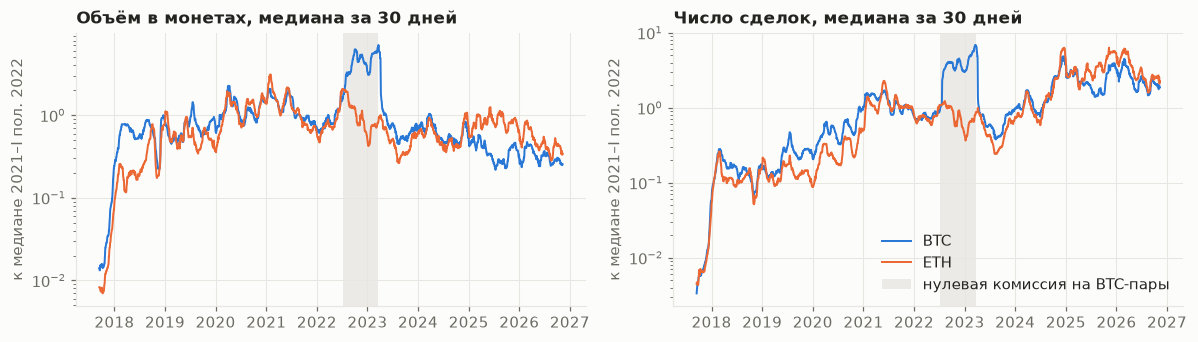

внутри / 180 дн. до  внутри / 180 дн. после
актив признак                                                  
BTC   volume                     4.6643                  6.5999
      trades                     5.0806                  7.0350
      quote_volume               2.6349                  4.6348
ETH   volume                     1.0560                  1.9316
      trades                     0.9917                  1.8664
      quote_volume               0.5998                  1.5819

,open,high,low,close,volume,trades
date,,,,,,
2018-02-06,"6,939.6300","7,878.0000","6,000.0100","7,652.1400","100,201.5003",785996
2018-02-07,"7,655.0200","8,476.0000","7,150.0100","7,599.0000","60,778.4605",514893
2018-02-08,"7,599.0000","7,844.0000","7,572.0900","7,784.0200","1,521.5373",12417
2018-02-09,"7,789.9000","8,738.0000","7,789.9000","8,683.9200","20,482.9108",273091
2018-02-10,"8,683.9300","9,065.7800","8,120.0000","8,533.9800","49,381.5127",537578
2018-02-11,"8,533.9900","8,549.0000","7,726.5300","8,063.8800","45,025.1880",524626


In [7]:
ZERO_FEE = (pd.Timestamp("2022-07-08"), pd.Timestamp("2023-03-21"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
for ax, column, title in zip(axes, ["volume", "trades"], ["Объём в монетах, медиана за 30 дней", "Число сделок, медиана за 30 дней"]):
    for name, df in ASSETS.items():
        series = df[column].rolling(30).median()
        ax.plot(series / series.loc["2021-01-01":"2022-06-30"].median(), color=ASSET_COLORS[name], label=name)
    ax.axvspan(*ZERO_FEE, color=GRID, alpha=0.8, lw=0, label="нулевая комиссия на BTC-пары")
    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_ylabel("к медиане 2021–I пол. 2022")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

rows = []
for name, df in ASSETS.items():
    for column in ["volume", "trades", "quote_volume"]:
        inside = df.loc[ZERO_FEE[0]:ZERO_FEE[1], column].median()
        before = df.loc[ZERO_FEE[0] - pd.Timedelta(days=180):ZERO_FEE[0] - pd.Timedelta(days=1), column].median()
        after = df.loc[ZERO_FEE[1] + pd.Timedelta(days=1):ZERO_FEE[1] + pd.Timedelta(days=180), column].median()
        rows.append({"актив": name, "признак": column, "внутри / 180 дн. до": inside / before, "внутри / 180 дн. после": inside / after})
display(pd.DataFrame(rows).set_index(["актив", "признак"]))
display(btc.loc["2018-02-06":"2018-02-11", ["open", "high", "low", "close", "volume", "trades"]])

**Результаты проверки.** Невозможных значений нет: цены и объёмы положительны, соотношения OHLC выполняются, объём покупок тейкеров не превышает общий, средневзвешенная цена дня лежит внутри диапазона low–high, значения Fear & Greed находятся в допустимых границах и согласованы с классами. Исправлять нечего, но найдены три особенности:

1. **ETH, сентябрь 2017.** В 4 днях цена открытия отличается от предыдущего закрытия на 1.1–1.5%. Это первые недели торгов с низкой ликвидностью (2–9 тыс. сделок в день). Дни лежат вне рабочей выборки, правка не нужна.
2. **BTC, 8 февраля 2018.** Всего 12 417 сделок против 514 893 накануне. В этот день Binance приостанавливала торги из-за затянувшегося обновления системы, поэтому свеча описывает неполный день. Цена закрытия корректна, строка сохраняется, но объём в этот день не отражает активность рынка.
3. **Структурный сдвиг объёма BTC, июль 2022 — март 2023.** Объём в монетах внутри периода выше в 4.7 раза, чем за 180 дней до него, и в 6.6 раза выше, чем за 180 дней после, число сделок — в 5.1 и 7.0 раза. У ETH соответствующие отношения для объёма в монетах 1.1 и 1.9, число сделок почти не изменилось относительно предыдущего периода (1.0). Сдвиг совпадает с программой нулевой комиссии Binance на BTC-пары, так что это эффект условий торговли, скорее всего связанный с ростом числа сделок ради оборота, а не со спросом на актив. На графике видно, что объём резко падает сразу после окончания программы.

**Как будет учтено.** Абсолютный объём BTC нельзя использовать как признак напрямую. Будет применяться логарифм объёма относительно собственного скользящего уровня (`volume_z30`) и бинарный флаг периода нулевой комиссии, а объём в USDT будет предпочтительнее объёма в монетах.

## 4. Выбросы

BTC: |robust z| > 5: 50 дней (1.48%); эксцесс 16.1, без 2020-03-12: 4.5; асимметрия -0.95, без 2020-03-12: -0.11


,log_return,robust_z,z_к_волатильности_30д
date,,,
2020-03-12,-0.5026,-23.1802,-15.7131
2018-01-16,-0.2169,-10.0157,-3.0697
2017-09-14,-0.2127,-9.8212,NaN
2017-12-07,0.2030,9.3275,3.9704
2021-02-08,0.1784,8.1985,3.5132
2022-06-13,-0.1670,-7.7175,-4.7063
2018-02-05,-0.1650,-7.6245,-2.4099
2019-04-02,0.1587,7.2879,12.6156


ETH: |robust z| > 5: 39 дней (1.16%); эксцесс 12.2, без 2020-03-12: 4.4; асимметрия -0.87, без 2020-03-12: -0.25


,log_return,robust_z,z_к_волатильности_30д
date,,,
2020-03-12,-0.5905,-19.7207,-9.9235
2021-05-19,-0.3249,-10.8581,-5.2379
2017-09-14,-0.2521,-8.4301,NaN
2018-01-16,-0.2398,-8.0206,-3.2642
2021-05-24,0.2338,7.7766,2.4718
2021-01-03,0.2335,7.7683,5.4120
2018-09-05,-0.2219,-7.4225,-4.6417
2020-03-13,0.2178,7.2454,1.7934


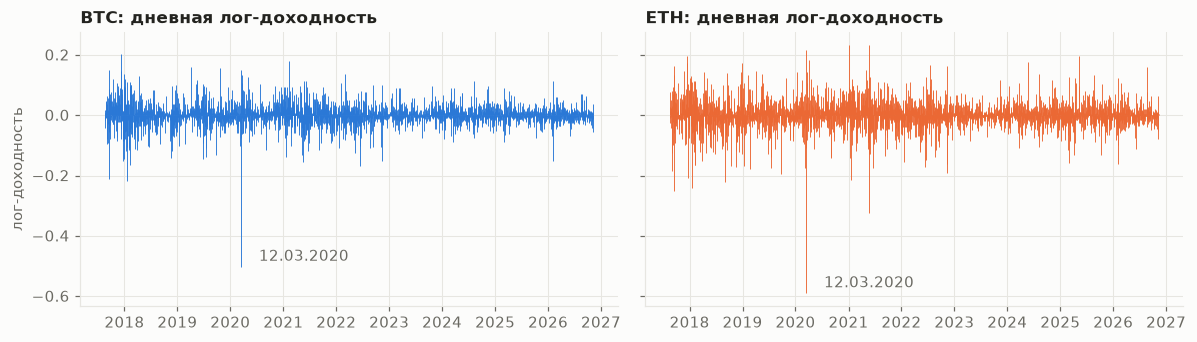

In [8]:
returns = pd.DataFrame({name: np.log(df["close"]).diff() for name, df in ASSETS.items()}).dropna()


def outlier_table(series, top=8):
    median = series.median()
    mad = 1.4826 * (series - median).abs().median()
    local_vol = series.rolling(30).std().shift()
    frame = pd.DataFrame({"log_return": series, "robust_z": (series - median) / mad, "z_к_волатильности_30д": series / local_vol})
    return frame.reindex(frame["robust_z"].abs().sort_values(ascending=False).index).head(top)


for name in returns:
    series = returns[name]
    robust = (series - series.median()) / (1.4826 * (series - series.median()).abs().median())
    no_covid = series.drop(pd.Timestamp("2020-03-12"))
    print(f"{name}: |robust z| > 5: {(robust.abs() > 5).sum()} дней ({(robust.abs() > 5).mean():.2%}); "
          f"эксцесс {series.kurt():.1f}, без 2020-03-12: {no_covid.kurt():.1f}; "
          f"асимметрия {series.skew():.2f}, без 2020-03-12: {no_covid.skew():.2f}")
    display(outlier_table(series))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, name in zip(axes, returns):
    ax.vlines(returns.index, 0, returns[name], color=ASSET_COLORS[name], lw=0.6)
    ax.set_title(f"{name}: дневная лог-доходность")
    idx = returns[name].idxmin()
    ax.annotate(idx.strftime("%d.%m.%Y"), (idx, returns[name].min()), xytext=(12, 4), textcoords="offset points", color=MUTED)
axes[0].set_ylabel("лог-доходность")
plt.tight_layout()
plt.show()

**Выводы по выбросам.** Для поиска используется робастный z-score (через медиану и MAD): обычный z-score сам искажён выбросами. Дней с |robust z| > 5 у BTC 50 (1.48%), у ETH 39 (1.16%).

Самый крупный выброс — **12 марта 2020 года** (ковидный обвал): −50.3% лог-доходности у BTC и −59.1% у ETH. Этот один день сильно влияет на статистики: эксцесс BTC падает с 16.1 до 4.5 при его исключении, асимметрия — с −0.95 до −0.11 (у ETH эксцесс с 12.2 до 4.4, асимметрия с −0.87 до −0.25). Отмеченные даты (март 2020, май 2021, июнь 2022) соответствуют реальным рыночным событиям, а не ошибкам данных.

**Решение: не удалять.** Это настоящие наблюдения, и именно в такие дни прогноз важнее всего. Удаление сделало бы оценку качества слишком оптимистичной. Вместо этого:

- для линейных моделей признаки будут винзоризоваться по квантилям, рассчитанным только на обучающем окне;
- основной метрикой регрессии будет MAE, менее чувствительная к выбросам, чем RMSE;
- в анализе ошибок на ЧП 7 такие дни будут рассматриваться отдельно.

## 5. Поведение отдельных рядов

### 5.1. Цены и доходности

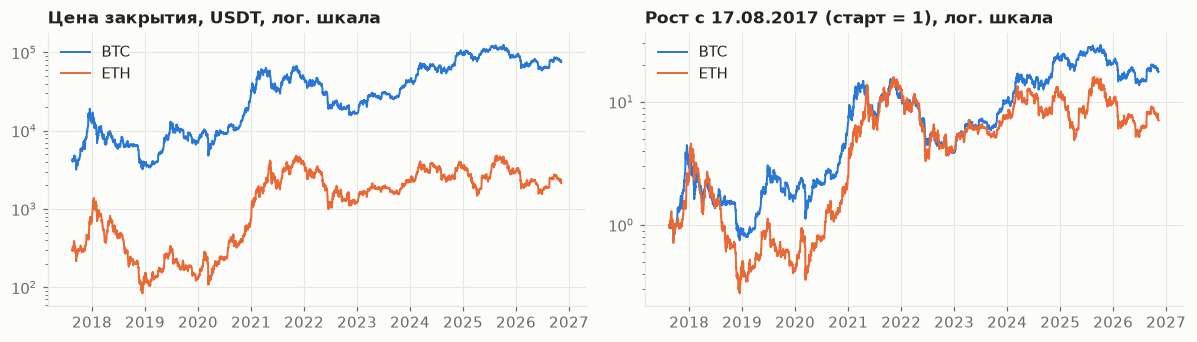

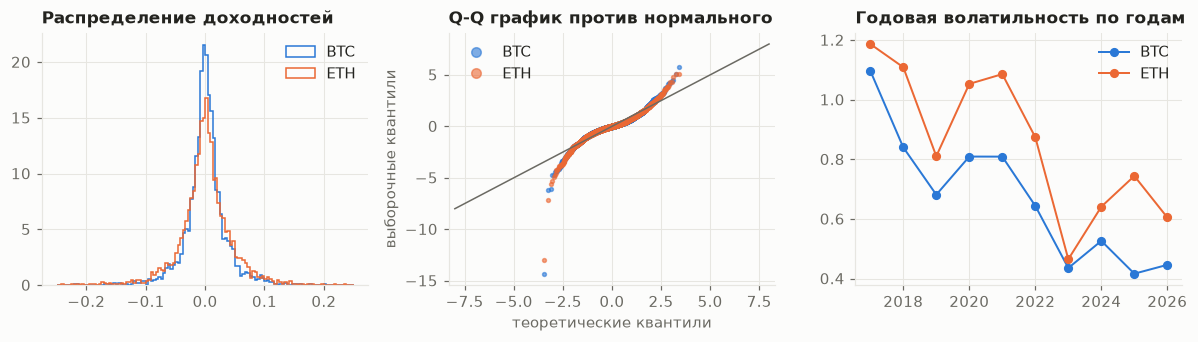

,BTC,ETH
средняя дневная доходность,0.0009,0.0006
стд. отклонение,0.0352,0.0455
годовая волатильность,0.6722,0.8693
асимметрия,-0.9546,-0.8741
эксцесс,16.0586,12.1631
доля дней роста,0.5111,0.5102
Jarque-Bera p-value,0.0000,0.0000


год,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
BTC,1.0974,0.8403,0.6816,0.8095,0.8093,0.6441,0.4357,0.5268,0.4167,0.4464
ETH,1.1870,1.1091,0.8107,1.0532,1.0860,0.8742,0.4653,0.6413,0.7444,0.6052


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for name, df in ASSETS.items():
    axes[0].plot(df["close"], color=ASSET_COLORS[name], label=name)
    axes[1].plot(df["close"] / df["close"].iloc[0], color=ASSET_COLORS[name], label=name)
axes[0].set_yscale("log")
axes[0].set_title("Цена закрытия, USDT, лог. шкала")
axes[1].set_yscale("log")
axes[1].set_title("Рост с 17.08.2017 (старт = 1), лог. шкала")
for ax in axes:
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for name in returns:
    axes[0].hist(returns[name], bins=120, range=(-0.25, 0.25), density=True, histtype="step", color=ASSET_COLORS[name], label=name)
    sm.ProbPlot(returns[name], dist=stats.norm, fit=True).qqplot(ax=axes[1], marker="o", markersize=2.5, markerfacecolor=ASSET_COLORS[name], markeredgecolor=ASSET_COLORS[name], alpha=0.6, label=name)
    vol = returns[name].groupby(returns.index.year).std() * np.sqrt(365)
    axes[2].plot(vol.index, vol.values, marker="o", markersize=5, color=ASSET_COLORS[name], label=name)
axes[0].set_title("Распределение доходностей")
axes[0].legend()
axes[1].plot([-8, 8], [-8, 8], color=MUTED, lw=1)
axes[1].set_title("Q-Q график против нормального")
axes[1].set_xlabel("теоретические квантили")
axes[1].set_ylabel("выборочные квантили")
axes[1].legend(markerscale=2.5)
axes[2].set_title("Годовая волатильность по годам")
axes[2].legend()
plt.tight_layout()
plt.show()

distribution = pd.DataFrame({name: {
    "средняя дневная доходность": returns[name].mean(), "стд. отклонение": returns[name].std(),
    "годовая волатильность": returns[name].std() * np.sqrt(365), "асимметрия": returns[name].skew(),
    "эксцесс": returns[name].kurt(), "доля дней роста": (returns[name] > 0).mean(),
    "Jarque-Bera p-value": stats.jarque_bera(returns[name]).pvalue,
} for name in returns})
display(distribution)
display((returns.groupby(returns.index.year).std() * np.sqrt(365)).rename_axis("год").T)

**Выводы.** Распределение доходностей далеко от нормального: тест Харке—Бера отвергает нормальность, на Q-Q графике видны тяжёлые хвосты с обеих сторон. Средняя дневная доходность мала по сравнению со стандартным отклонением (BTC: 0.085% при 3.52%, ETH: 0.058% при 4.55%), доля дней роста близка к половине (51.1% и 51.0%). ETH волатильнее BTC: 86.9% против 67.2% годовых.

Волатильность заметно снизилась со временем: у BTC с 110% в 2017 году и примерно 81% в 2020–2021 годах до 42–53% в 2023–2026 годах. Поэтому данные неоднородны, и обучающая часть с 2018 по 2021 год описывает иной режим рынка, нежели последние годы.

### 5.2. Тренд и сезонность

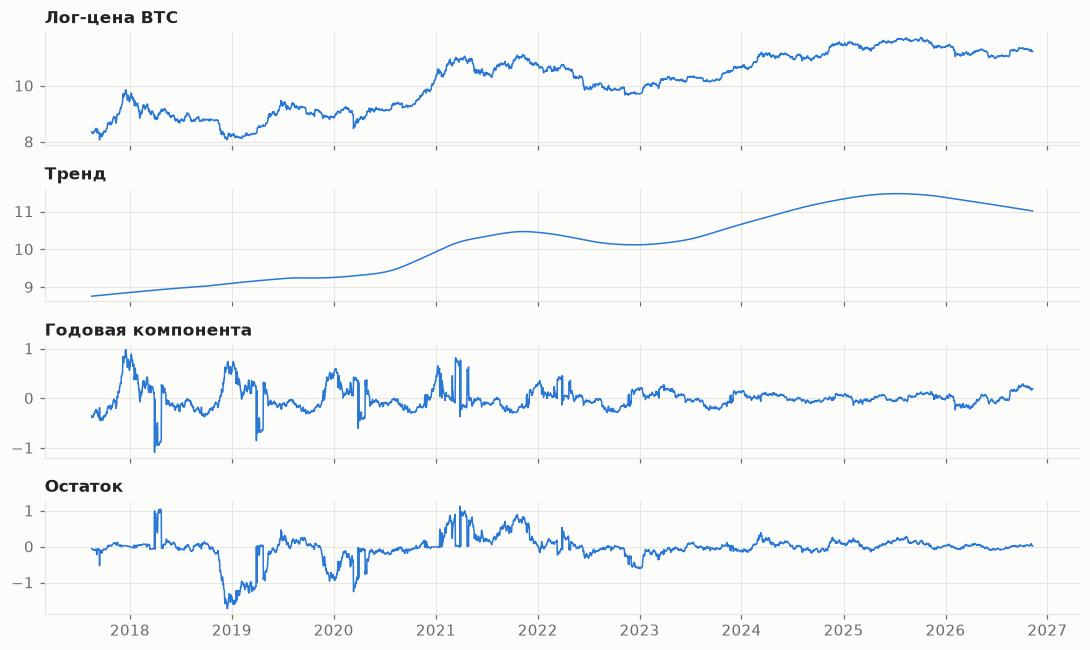

сила сезонности, факт  плацебо, среднее  плацебо, 95-й перцентиль  доля плацебо не слабее факта
актив период, дней                                                                                                 
BTC   7                            0.6739            0.6496                    0.6798                        0.1000
      365                          0.7736            0.5725                    0.8032                        0.1000
ETH   7                            0.6346            0.6003                    0.6199                        0.0333
      365                          0.9125            0.6238                    0.7781                        0.0000

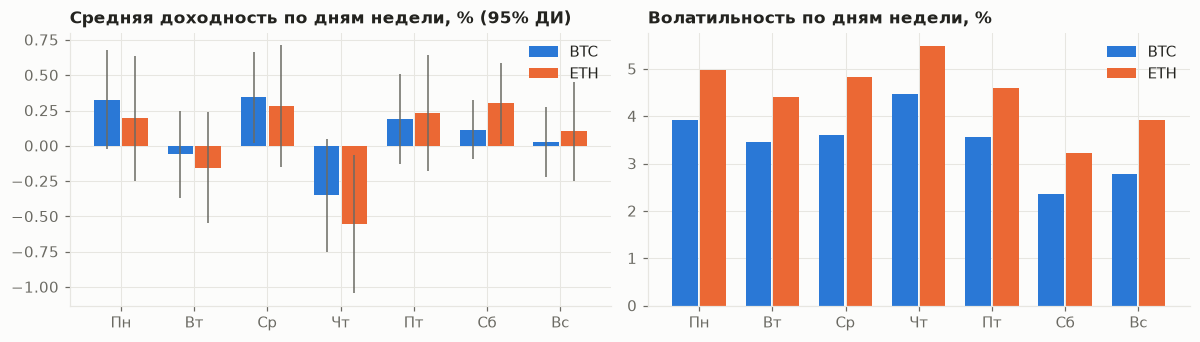

,"Краскел—Уоллис, день недели p","Краскел—Уоллис, месяц p","Левене (волатильность), день недели p","Левене (волатильность), месяц p"
актив,,,,
BTC,0.1330,0.8686,0.0000,0.0000
ETH,0.0081,0.6837,0.0000,0.0000


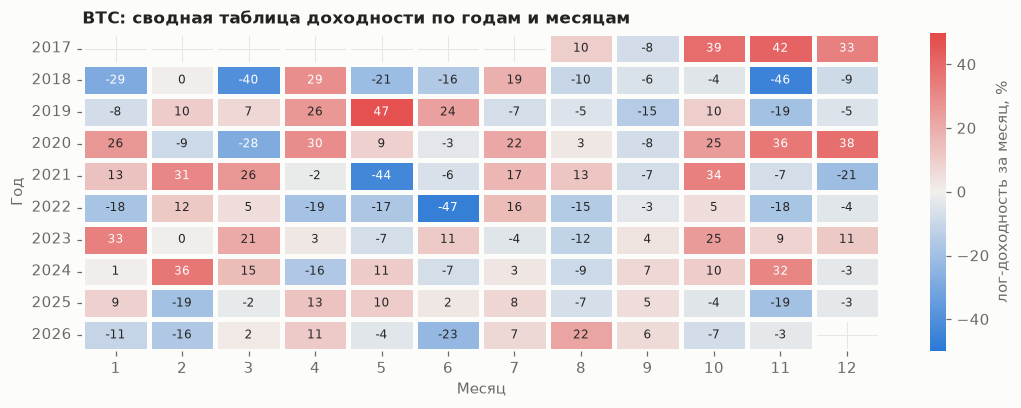

In [10]:
def seasonal_strength(series, period):
    result = STL(series, period=period, robust=True).fit()
    resid_weight = result.weights
    return max(0.0, 1 - np.average(result.resid ** 2, weights=resid_weight)
               / np.average((result.seasonal + result.resid) ** 2, weights=resid_weight))


btc_log = np.log(btc["close"]).asfreq("D")
stl_year = STL(btc_log, period=365, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(10, 6), sharex=True)
parts = [("Лог-цена BTC", btc_log), ("Тренд", stl_year.trend), ("Годовая компонента", stl_year.seasonal), ("Остаток", stl_year.resid)]
for ax, (title, series) in zip(axes, parts):
    ax.plot(series, color=BLUE, lw=1)
    ax.set_title(title)
plt.tight_layout()
plt.show()

# Плацебо: перемешиваем блоки доходностей по 30 дней и собираем из них новый ряд.
# Блоки сохраняют кластеры волатильности, а календарная привязка разрушается:
# настоящей недельной и годовой сезонности в таком ряду нет по построению.
def block_shuffle(values, rng, block=30):
    starts = np.arange(0, len(values), block)
    return np.concatenate([values[start:start + block] for start in rng.permutation(starts)])


rng = np.random.default_rng(42)
rows = []
for name, df in ASSETS.items():
    log_close = np.log(df["close"]).asfreq("D")
    diffs = log_close.diff().dropna().to_numpy()
    for period in (7, 365):
        placebo = [seasonal_strength(pd.Series(np.r_[0.0, block_shuffle(diffs, rng)].cumsum(), index=log_close.index), period) for _ in range(30)]
        actual = seasonal_strength(log_close, period)
        rows.append({"актив": name, "период, дней": period, "сила сезонности, факт": actual,
                     "плацебо, среднее": np.mean(placebo), "плацебо, 95-й перцентиль": np.quantile(placebo, 0.95),
                     "доля плацебо не слабее факта": np.mean(np.array(placebo) >= actual)})
display(pd.DataFrame(rows).set_index(["актив", "период, дней"]))

labels = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
width = 0.38
for offset, name in zip([-width / 2, width / 2], returns):
    group = returns[name].groupby(returns.index.day_of_week)
    mean, err = group.mean() * 100, 1.96 * group.sem() * 100
    axes[0].bar(np.arange(7) + offset, mean, width - 0.03, yerr=err, color=ASSET_COLORS[name], ecolor=MUTED, error_kw={"lw": 1}, label=name)
    axes[1].bar(np.arange(7) + offset, group.std() * 100, width - 0.03, color=ASSET_COLORS[name], label=name)
axes[0].set_title("Средняя доходность по дням недели, % (95% ДИ)")
axes[1].set_title("Волатильность по дням недели, %")
for ax in axes:
    ax.set_xticks(range(7), labels)
    ax.legend()
plt.tight_layout()
plt.show()

rows = []
for name in returns:
    by_day = [v.values for _, v in returns[name].groupby(returns.index.day_of_week)]
    by_month = [v.values for _, v in returns[name].groupby(returns.index.month)]
    rows.append({"актив": name, "Краскел—Уоллис, день недели p": stats.kruskal(*by_day).pvalue,
                 "Краскел—Уоллис, месяц p": stats.kruskal(*by_month).pvalue,
                 "Левене (волатильность), день недели p": stats.levene(*by_day).pvalue,
                 "Левене (волатильность), месяц p": stats.levene(*by_month).pvalue})
display(pd.DataFrame(rows).set_index("актив"))

monthly = returns["BTC"].groupby([returns.index.year, returns.index.month]).sum().unstack() * 100
monthly.index.name, monthly.columns.name = "Год", "Месяц"
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(monthly, annot=True, fmt=".0f", cmap=DIVERGING, center=0, vmin=-50, vmax=50, linewidths=2, linecolor=SURFACE,
            cbar_kws={"label": "лог-доходность за месяц, %"}, ax=ax, annot_kws={"size": 8})
ax.set_title("BTC: сводная таблица доходности по годам и месяцам")
plt.tight_layout()
plt.show()

**Тренд.** Лог-цены имеют выраженный восходящий тренд с многолетними циклами «рост—падение» (пики конца 2017, 2021 и 2025 годов).

**Сезонность в средней доходности практически отсутствует.**

- *STL и контрольный эксперимент.* Сила сезонности на лог-цене выглядит высокой (0.63–0.91), но эта величина обманчива: ряды с перемешанными блоками по 30 дней, где сезонности нет по построению, дают в среднем 0.57–0.65. Для BTC факт не выходит за 95-й перцентиль плацебо ни на одном из периодов. Для ETH отличие есть, но годовая компонента не подтверждается тестом по месяцам и, скорее всего, отражает несколько крупных циклов на коротком (9 лет) ряду. Число перестановок равно 30, поэтому оценка грубая.
- *Месяцы.* Тест Краскела—Уоллиса не находит различий (p = 0.87 для BTC, 0.68 для ETH). На сводной таблице одни и те же месяцы в разные годы имеют разный знак: например, ноябрь у BTC от +42% (2017) до −46% (2018).
- *Дни недели.* Для BTC различий нет (p = 0.13). Для ETH различия значимы (p = 0.008): доля роста в субботу 57.3%, в четверг 45.1%. Эффект слабый и требует проверки вне выборки.

**Сезонность волатильности есть.** Тест Левене значим и для дней недели, и для месяцев. Стандартное отклонение BTC в субботу 2.4% и в воскресенье 2.8% против 3.5–4.5% в будни, что соответствует закрытым традиционным рынкам в выходные. Высокий показатель четверга (4.5%) во многом объясняется тем, что на четверг пришлось 12 марта 2020 года: без этого дня он равен 3.9%, на уровне понедельника. Различия по месяцам, вероятно, связаны с концентрацией кризисов в отдельных месяцах, а не с календарём.

**Как будет использовано.** Циклические признаки дня недели и флаг выходного будут добавлены в первую очередь для прогноза волатильности. SARIMA с годовым периодом и календарные признаки месяца для прогноза доходности не планируются.

### 5.3. Стационарность (ADF и KPSS)

In [11]:
def stationarity(series):
    series = series.dropna()
    adf_stat, adf_p, *_ = adfuller(series, autolag="AIC")
    kpss_stat, kpss_p, *_ = kpss(series, regression="c", nlags="auto")
    verdict = {(True, True): "стационарен", (False, False): "нестационарен",
               (True, False): "неоднозначно (оба теста отвергают H0): вероятны сдвиги уровня", (False, True): "неоднозначно (оба теста не отвергают H0)"}
    return {"ADF": adf_stat, "ADF p": adf_p, "KPSS": kpss_stat, "KPSS p (границы 0.01–0.1)": kpss_p,
            "вывод": verdict[(adf_p < 0.05, kpss_p >= 0.05)]}


series_map = {
    "BTC лог-цена": np.log(btc["close"]), "BTC лог-доходность": returns["BTC"],
    "BTC лог-объём (USDT)": np.log(btc["quote_volume"]), "BTC волатильность 30д": returns["BTC"].rolling(30).std(),
    "ETH лог-цена": np.log(eth["close"]), "ETH лог-доходность": returns["ETH"],
    "ETH лог-объём (USDT)": np.log(eth["quote_volume"]), "ETH волатильность 30д": returns["ETH"].rolling(30).std(),
    "Fear & Greed": clean["fng_value"], "S&P 500 лог-уровень": np.log(clean["sp500_close"]),
    "S&P 500 лог-доходность": np.log(clean["sp500_close"]).diff(), "DXY лог-уровень": np.log(clean["dxy_close"]),
    "DXY лог-доходность": np.log(clean["dxy_close"]).diff(),
}
pd.DataFrame({name: stationarity(series) for name, series in series_map.items()}).T

,ADF,ADF p,KPSS,KPSS p (границы 0.01–0.1),вывод
BTC лог-цена,-1.5055,0.5308,7.3421,0.0100,нестационарен
BTC лог-доходность,-40.3166,0.0000,0.0808,0.1000,стационарен
BTC лог-объём (USDT),-4.4001,0.0003,4.3729,0.0100,неоднозначно (оба теста отвергают H0): вероятн...
BTC волатильность 30д,-5.7937,0.0000,3.2381,0.0100,неоднозначно (оба теста отвергают H0): вероятн...
ETH лог-цена,-1.3681,0.5974,6.0463,0.0100,нестационарен
ETH лог-доходность,-40.3099,0.0000,0.0952,0.1000,стационарен
ETH лог-объём (USDT),-3.4956,0.0081,5.2075,0.0100,неоднозначно (оба теста отвергают H0): вероятн...
ETH волатильность 30д,-6.1646,0.0000,2.8084,0.0100,неоднозначно (оба теста отвергают H0): вероятн...
Fear & Greed,-6.0185,0.0000,0.3384,0.1000,стационарен
S&P 500 лог-уровень,-0.3579,0.9169,8.0798,0.0100,нестационарен


**Выводы.** Логика совместного применения тестов: нулевая гипотеза ADF — наличие единичного корня, KPSS — стационарность.

- **Лог-цены BTC и ETH, лог-уровни S&P 500 и DXY нестационарны:** ADF не отвергает единичный корень (p = 0.53 и 0.60 для BTC и ETH), KPSS отвергает стационарность.
- **Лог-доходности всех активов стационарны:** ADF отвергает единичный корень (статистика около −40 у криптовалют), KPSS стационарность не отвергает. Значит, работать надо с доходностями. ARIMA на лог-цене потребует дифференцирования (d = 1).
- **Fear & Greed стационарен** и может использоваться без преобразований.
- **Лог-объём и 30-дневная волатильность дают неоднозначный результат:** оба теста отвергают свои нулевые гипотезы. Такая картина типична для рядов со сдвигами уровня и длинной памятью, что согласуется с разделом 3 и снижением волатильности. Поэтому объём будет нормироваться к собственному скользящему уровню.

### 5.4. Автокорреляция и кластеризация волатильности

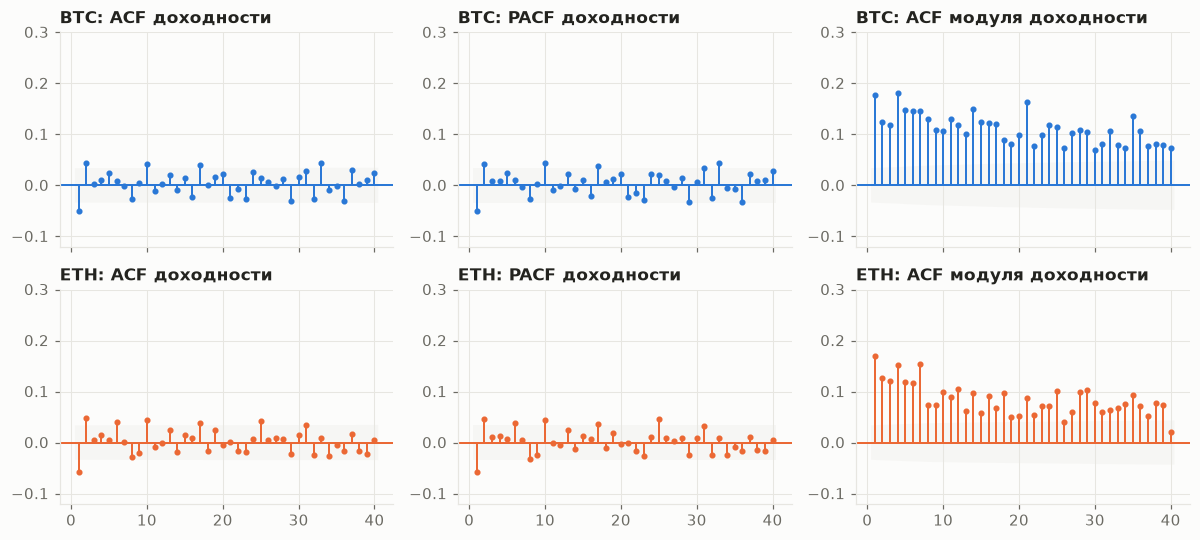

BTC: Ljung-Box(10) доходности p=0.0032, модуля p=1.1e-136; ARCH-LM(10) p=1.8e-12
ETH: Ljung-Box(10) доходности p=0.0001, модуля p=7.4e-106; ARCH-LM(10) p=3.3e-19


AR(1) коэффициент  t (Newey—West)      p
актив период                                             
BTC   весь ряд             -0.0505         -1.8564 0.0634
      2018–2021            -0.0828         -2.3557 0.0185
      2022–2026            -0.0263         -0.8605 0.3895
ETH   весь ряд             -0.0583         -2.2992 0.0215
      2018–2021            -0.0900         -2.6069 0.0091
      2022–2026            -0.0178         -0.6625 0.5077

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True)
for row, name in enumerate(returns):
    color = ASSET_COLORS[name]
    style = dict(lags=40, zero=False, color=color, vlines_kwargs={"colors": color}, markersize=3)
    plot_acf(returns[name], ax=axes[row, 0], title=f"{name}: ACF доходности", **style)
    plot_pacf(returns[name], ax=axes[row, 1], title=f"{name}: PACF доходности", method="ywm", **style)
    plot_acf(returns[name].abs(), ax=axes[row, 2], title=f"{name}: ACF модуля доходности", **style)
for ax in axes.ravel():
    ax.set_ylim(-0.12, 0.3)
    for collection in ax.collections:
        if collection.__class__.__name__ in ("PolyCollection", "FillBetweenPolyCollection"):
            collection.set_facecolor(GRID)
plt.tight_layout()
plt.show()

rows = []
for name in returns:
    r = returns[name]
    lb_r, lb_abs = acorr_ljungbox(r, lags=[10]).iloc[0], acorr_ljungbox(r.abs(), lags=[10]).iloc[0]
    arch_stat, arch_p, *_ = het_arch(r, nlags=10)
    for period, sub in [("весь ряд", r), ("2018–2021", r.loc["2018":"2021"]), ("2022–2026", r.loc["2022":"2026"])]:
        frame = pd.DataFrame({"y": sub, "lag": sub.shift()}).dropna()
        model = sm.OLS(frame["y"], sm.add_constant(frame["lag"])).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        rows.append({"актив": name, "период": period, "AR(1) коэффициент": model.params["lag"], "t (Newey—West)": model.tvalues["lag"], "p": model.pvalues["lag"]})
    print(f"{name}: Ljung-Box(10) доходности p={lb_r['lb_pvalue']:.4f}, модуля p={lb_abs['lb_pvalue']:.1e}; ARCH-LM(10) p={arch_p:.1e}")
display(pd.DataFrame(rows).set_index(["актив", "период"]))

alpha   beta  alpha+beta  полураспад шока, дней  nu (степени свободы t)
актив период                                                                            
BTC   весь ряд  0.0706 0.9294      1.0000                    NaN                  3.1817
      2022–2026 0.0758 0.9150      0.9909                75.6059                  2.9838
ETH   весь ряд  0.1094 0.8906      1.0000                    NaN                  3.2413
      2022–2026 0.0913 0.9087      1.0000                    NaN                  3.0870

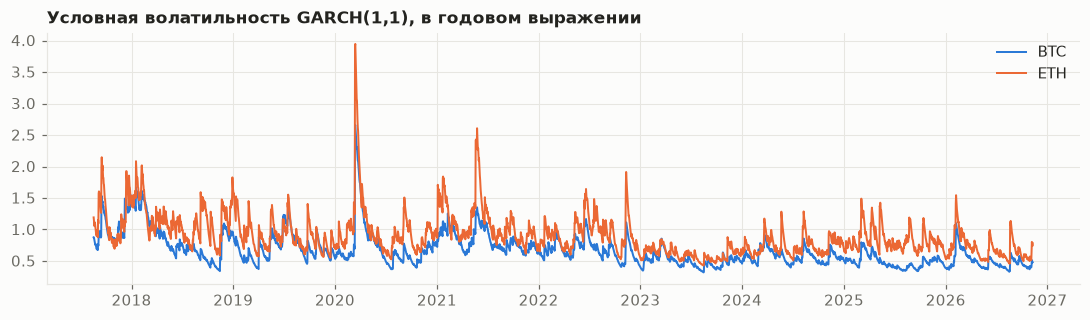

In [13]:
garch_rows, conditional = [], {}
for name in returns:
    for period, sample in [("весь ряд", returns[name]), ("2022–2026", returns[name].loc["2022":"2026"])]:
        fitted = arch_model(sample * 100, mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
        params = fitted.params
        persistence = params["alpha[1]"] + params["beta[1]"]
        garch_rows.append({"актив": name, "период": period, "alpha": params["alpha[1]"], "beta": params["beta[1]"], "alpha+beta": persistence,
                           "полураспад шока, дней": np.log(0.5) / np.log(persistence) if persistence < 0.9999 else np.nan,
                           "nu (степени свободы t)": params["nu"]})
        if period == "весь ряд":
            conditional[name] = fitted.conditional_volatility
display(pd.DataFrame(garch_rows).set_index(["актив", "период"]))

fig, ax = plt.subplots(figsize=(10, 3))
for name in returns:
    ax.plot(conditional[name] * np.sqrt(365) / 100, color=ASSET_COLORS[name], label=name)
ax.set_title("Условная волатильность GARCH(1,1), в годовом выражении")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Выводы.**

- **Доходности почти не автокоррелированы.** ACF на первом лаге мала и отрицательна (−0.051 для BTC, −0.058 для ETH). Тест Льюнга—Бокса формально отвергает отсутствие автокорреляции (p = 0.003 и 0.0001), но обычные доверительные интервалы и этот тест завышают значимость при изменяющейся волатильности. С устойчивыми к гетероскедастичности ошибками Ньюи—Уэста коэффициент AR(1) у BTC незначим на уровне 5% (p = 0.063), у ETH значим (p = 0.022).
- **Эффект нестабилен.** В 2018–2021 годах коэффициент AR(1) составлял −0.083 для BTC и −0.090 для ETH (оба значимы), в 2022–2026 годах −0.026 и −0.018 (p = 0.39 и 0.51). Лёгкий разворот после вчерашнего движения исчез вместе со снижением волатильности и ростом зрелости рынка.
- **Волатильность кластеризуется.** ACF модуля доходности значима и убывает медленно: 0.18 и 0.17 на первом лаге и около 0.07–0.08 на лаге 40 для BTC. Тесты Льюнга—Бокса для модуля и ARCH-LM отвергают отсутствие эффекта с p-value порядка 10⁻¹² и меньше.
- **GARCH(1,1).** На всей выборке сумма alpha + beta равна 1.00 у обоих активов, то есть модель упирается в границу устойчивости (интегрированный GARCH). Это обычно указывает на сдвиги уровня волатильности или длинную память. На периоде 2022–2026 годов у BTC сумма равна 0.991 (полураспад шока около 76 дней), у ETH по-прежнему 1.00. Число степеней свободы распределения Стьюдента около 3: хвосты настолько тяжёлые, что четвёртый момент распределения может не существовать, поэтому выборочному эксцессу доверять нельзя.

**Как будет использовано.** Прогноз самой доходности — трудная задача, а прогноз её величины намного реалистичнее. В признаки войдут скользящие меры волатильности разных окон, а для интервальной оценки прогноза будет использоваться GARCH-подобная модель с тяжёлыми хвостами.

## 6. Взаимосвязь BTC и ETH

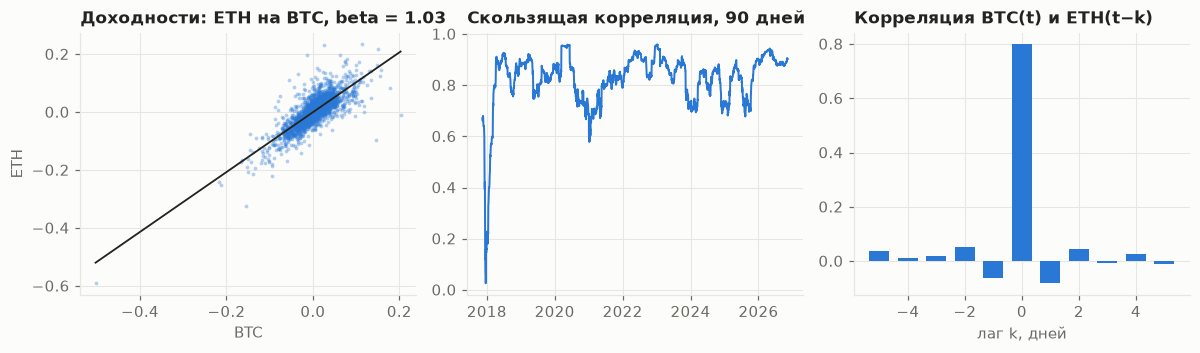

Корреляция доходностей: Пирсон 0.799, Спирмен 0.789
Корреляция лог-цен: 0.919
Минимум 90-дневной корреляции: 0.026 (2017-12-20); с 2019 г. минимум 0.579 (2021-01-09)
Медиана 90-дневной корреляции с 2019 г.: 0.851
Тест на коинтеграцию (Энгл—Грейнджер) лог-цен: статистика -2.43, p-value 0.311


,-5,-4,-3,-2,-1,0,1,2,3,4,5
corr,0.0368,0.0101,0.0176,0.0514,-0.0605,0.7987,-0.0813,0.0446,-0.0083,0.0272,-0.0103


In [14]:
rolling_corr = returns["BTC"].rolling(90).corr(returns["ETH"])
beta = np.polyfit(returns["BTC"], returns["ETH"], 1)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
axes[0].scatter(returns["BTC"], returns["ETH"], s=6, alpha=0.35, color=BLUE, linewidths=0)
x = np.array([returns["BTC"].min(), returns["BTC"].max()])
axes[0].plot(x, beta[0] * x + beta[1], color=INK, lw=1.2)
axes[0].set_title(f"Доходности: ETH на BTC, beta = {beta[0]:.2f}")
axes[0].set_xlabel("BTC")
axes[0].set_ylabel("ETH")
axes[1].plot(rolling_corr, color=BLUE)
axes[1].set_title("Скользящая корреляция, 90 дней")
axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
lags = range(-5, 6)
ccf = [returns["BTC"].corr(returns["ETH"].shift(k)) for k in lags]
axes[2].bar(lags, ccf, color=BLUE, width=0.7)
axes[2].set_title("Корреляция BTC(t) и ETH(t−k)")
axes[2].set_xlabel("лаг k, дней")
plt.tight_layout()
plt.show()

print(f"Корреляция доходностей: Пирсон {returns['BTC'].corr(returns['ETH']):.3f}, Спирмен {returns['BTC'].corr(returns['ETH'], method='spearman'):.3f}")
print(f"Корреляция лог-цен: {np.log(btc['close']).corr(np.log(eth['close'])):.3f}")
print(f"Минимум 90-дневной корреляции: {rolling_corr.min():.3f} ({rolling_corr.idxmin().date()}); с 2019 г. минимум {rolling_corr.loc['2019':].min():.3f} ({rolling_corr.loc['2019':].idxmin().date()})")
print(f"Медиана 90-дневной корреляции с 2019 г.: {rolling_corr.loc['2019':].median():.3f}")
stat, p, _ = coint(np.log(btc["close"]), np.log(eth["close"]))
print(f"Тест на коинтеграцию (Энгл—Грейнджер) лог-цен: статистика {stat:.2f}, p-value {p:.3f}")
display(pd.Series(ccf, index=lags, name="corr").to_frame().T)

**Выводы.** Доходности BTC и ETH тесно связаны одновременно: корреляция 0.80 (Спирмен 0.79), beta ETH к BTC 1.03. С 2019 года медиана 90-дневной корреляции равна 0.85, минимум 0.58 (январь 2021). Низкие значения в конце 2017 года относятся к первым месяцам торгов ETH на бирже.

Высокая корреляция уровней (0.92) не означает устойчивого равновесия: тест Энгла—Грейнджера коинтеграцию не находит (p = 0.31). Поэтому торговать спред или использовать механизм коррекции ошибок нет оснований.

Лидера нет: корреляции с лагами ±1 малы и обе отрицательны (−0.081 и −0.061), пик находится на нуле лагов. Вероятно, информация между активами распространяется внутри дня, и дневные данные этого не улавливают. Поскольку значения ETH и BTC за один и тот же день сильно коррелированы, в модели достаточно одного из них или их разности, а признаки «сегодняшний ETH» и «сегодняшний BTC» создают мультиколлинеарность.

## 7. Признаки и их связь с целевой переменной

Целевые переменные для дня `t`: `target_ret` — лог-доходность за день `t+1`, `target_up` — направление, `target_abs` — модуль доходности. Все признаки считаются только по данным, доступным на момент закрытия дня `t` (00:00 UTC следующего дня). S&P 500 и DXY закрываются раньше этого момента, Fear & Greed за день `t` публикуется в начале дня `t`, поэтому заглядывания в будущее нет.

In [15]:
def build_dataset(df, other):
    close = df["close"]
    log_close = np.log(close)
    ret = log_close.diff()
    delta = close.diff()
    gain = delta.clip(lower=0).ewm(alpha=1 / 14, adjust=False).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1 / 14, adjust=False).mean()
    macd = close.ewm(span=12, adjust=False).mean() - close.ewm(span=26, adjust=False).mean()
    log_volume = np.log(df["quote_volume"])

    data = pd.DataFrame(index=df.index)
    data["ret_1"] = ret
    data["ret_lag_1"] = ret.shift(1)
    data["ret_7"] = log_close.diff(7)
    data["ret_30"] = log_close.diff(30)
    data["vol_7"] = ret.rolling(7).std()
    data["vol_30"] = ret.rolling(30).std()
    data["hl_range"] = np.log(df["high"] / df["low"])
    data["volume_z30"] = (log_volume - log_volume.rolling(30).mean()) / log_volume.rolling(30).std()
    data["taker_buy_share"] = df["taker_buy_quote"] / df["quote_volume"]
    data["rsi_14"] = 100 - 100 / (1 + gain / loss)
    data["macd_hist"] = (macd - macd.ewm(span=9, adjust=False).mean()) / close
    data["dist_sma20"] = close / close.rolling(20).mean() - 1
    data["dist_sma50"] = close / close.rolling(50).mean() - 1
    data["other_ret_1"] = np.log(other["close"]).diff()
    data["sp500_ret"] = np.log(clean["sp500_close"]).diff()
    data["dxy_ret"] = np.log(clean["dxy_close"]).diff()
    data["fng"] = clean["fng_value"]
    data["target_ret"] = ret.shift(-1)
    data["target_up"] = (data["target_ret"] > 0).astype(float).where(data["target_ret"].notna())
    data["target_abs"] = data["target_ret"].abs()
    return data.dropna()


datasets = {"BTC": build_dataset(btc, eth), "ETH": build_dataset(eth, btc)}
FEATURES = [c for c in datasets["BTC"].columns if not c.startswith("target")]
for name, data in datasets.items():
    print(name, data.shape, data.index.min().date(), "—", data.index.max().date())
datasets["BTC"].describe().T

BTC (3202, 20) 2018-02-02 — 2026-11-08
ETH (3202, 20) 2018-02-02 — 2026-11-08


,count,mean,std,min,25%,50%,75%,max
ret_1,"3,202.0000",0.0007,0.0333,-0.5026,-0.0134,0.0004,0.0148,0.1784
ret_lag_1,"3,202.0000",0.0006,0.0334,-0.5026,-0.0134,0.0004,0.0148,0.1784
ret_7,"3,202.0000",0.0043,0.0887,-0.6347,-0.0368,0.0037,0.0483,0.3469
ret_30,"3,202.0000",0.0174,0.1918,-0.9000,-0.0878,0.0145,0.1280,0.7867
vol_7,"3,202.0000",0.0285,0.0174,0.0031,0.0171,0.0247,0.0356,0.2114
vol_30,"3,202.0000",0.0306,0.0138,0.0088,0.0215,0.0282,0.0365,0.1108
hl_range,"3,202.0000",0.0465,0.0348,0.0034,0.0248,0.0380,0.0569,0.5913
volume_z30,"3,202.0000",-0.0090,1.0593,-4.3091,-0.7130,-0.0176,0.7057,4.0560
taker_buy_share,"3,202.0000",0.4965,0.0255,0.3796,0.4810,0.4963,0.5102,0.6153
rsi_14,"3,202.0000",51.8363,13.5308,10.4978,42.6889,50.6951,60.8395,89.9922


In [16]:
def association_table(data, name):
    rows = []
    for feature in FEATURES:
        x = sm.add_constant(data[feature] / data[feature].std())
        hac = dict(cov_type="HAC", cov_kwds={"maxlags": 10})
        fit_ret, fit_abs = sm.OLS(data["target_ret"], x).fit(**hac), sm.OLS(data["target_abs"], x).fit(**hac)
        early, late = data.loc["2018":"2021"], data.loc["2022":"2026"]
        rows.append({
            "актив": name, "признак": feature,
            "Пирсон с ret": data[feature].corr(data["target_ret"]),
            "Спирмен с ret": data[feature].corr(data["target_ret"], method="spearman"),
            "t (NW)": fit_ret.tvalues[feature], "p": fit_ret.pvalues[feature],
            "ret 2018–21": early[feature].corr(early["target_ret"]),
            "ret 2022–26": late[feature].corr(late["target_ret"]),
            "Спирмен с |ret|": data[feature].corr(data["target_abs"], method="spearman"),
            "t |ret| (NW)": fit_abs.tvalues[feature], "p |ret|": fit_abs.pvalues[feature],
        })
    return pd.DataFrame(rows)


association = pd.concat([association_table(data, name) for name, data in datasets.items()], ignore_index=True)
association["p_BH"] = multipletests(association["p"], method="fdr_bh")[1]
association["p_BH |ret|"] = multipletests(association["p |ret|"], method="fdr_bh")[1]
association["знак стабилен"] = np.sign(association["ret 2018–21"]) == np.sign(association["ret 2022–26"])
columns = ["Пирсон с ret", "Спирмен с ret", "t (NW)", "p", "p_BH", "ret 2018–21", "ret 2022–26", "знак стабилен", "Спирмен с |ret|", "t |ret| (NW)", "p_BH |ret|"]
for name in datasets:
    print(name)
    display(association[association["актив"] == name].set_index("признак")[columns].sort_values("Спирмен с |ret|", key=abs, ascending=False))
print("Значимы для доходности после поправки BH (p_BH < 0.05):")
display(association.loc[association["p_BH"] < 0.05, ["актив", "признак", "Пирсон с ret", "t (NW)", "p_BH", "знак стабилен"]])

BTC


,Пирсон с ret,Спирмен с ret,t (NW),p,p_BH,ret 2018–21,ret 2022–26,знак стабилен,Спирмен с |ret|,t |ret| (NW),p_BH |ret|
признак,,,,,,,,,,,
vol_30,0.0146,-0.0001,0.7414,0.4585,0.6010,0.0184,-0.0112,False,0.2744,7.6240,0.0000
vol_7,0.0145,0.0011,0.6824,0.4950,0.6010,0.0286,-0.0268,False,0.2447,11.5377,0.0000
hl_range,0.0257,0.0152,1.3253,0.1851,0.4195,0.0351,-0.0025,False,0.2383,11.3166,0.0000
volume_z30,0.0082,0.0141,0.5062,0.6127,0.6944,0.0147,0.0003,True,0.0701,4.0741,0.0002
other_ret_1,-0.0800,-0.0813,-3.3274,0.0009,0.0298,-0.1079,-0.0297,True,-0.0598,-3.6829,0.0009
ret_1,-0.0679,-0.0631,-2.4713,0.0135,0.0763,-0.0902,-0.0263,True,-0.0398,-2.9634,0.0103
dxy_ret,0.0125,0.0123,0.6517,0.5146,0.6033,0.0401,-0.0136,False,-0.0379,-0.6441,0.5520
rsi_14,0.0398,0.0141,2.1149,0.0344,0.1301,0.0499,0.0271,True,-0.0364,-1.9433,0.0930
dist_sma50,0.0194,0.0217,0.9352,0.3497,0.5404,0.0180,0.0192,True,-0.0355,-1.2078,0.2860


ETH


,Пирсон с ret,Спирмен с ret,t (NW),p,p_BH,ret 2018–21,ret 2022–26,знак стабилен,Спирмен с |ret|,t |ret| (NW),p_BH |ret|
признак,,,,,,,,,,,
vol_7,0.0071,0.0021,0.4121,0.6803,0.7228,0.0263,-0.0413,False,0.2499,9.8426,0.0000
hl_range,0.0308,0.0198,1.6447,0.1000,0.2616,0.0551,-0.0218,False,0.2247,9.5915,0.0000
vol_30,0.0044,-0.0033,0.2646,0.7913,0.7913,0.0020,-0.0121,False,0.2235,6.5722,0.0000
volume_z30,0.0182,0.0181,1.0435,0.2967,0.5309,0.0402,-0.0101,False,0.0884,4.5363,0.0000
fng,0.0486,0.0345,2.5550,0.0106,0.0722,0.0621,0.0325,True,-0.0414,-2.1347,0.0660
ret_7,0.0185,0.0068,0.9359,0.3493,0.5404,0.0234,0.0085,True,-0.0329,-2.7053,0.0178
other_ret_1,-0.0753,-0.0715,-2.7324,0.0063,0.0534,-0.1036,-0.0243,True,-0.0321,-2.9090,0.0112
ret_1,-0.0735,-0.0782,-2.8714,0.0041,0.0463,-0.1056,-0.0178,True,-0.0298,-2.7744,0.0157
macd_hist,0.0167,0.0021,0.8481,0.3964,0.5859,0.0288,-0.0061,False,-0.0241,-2.1321,0.0660


Значимы для доходности после поправки BH (p_BH < 0.05):


,актив,признак,Пирсон с ret,t (NW),p_BH,знак стабилен
13,BTC,other_ret_1,-0.0800,-3.3274,0.0298,True
17,ETH,ret_1,-0.0735,-2.8714,0.0463,True
18,ETH,ret_lag_1,0.0603,2.9760,0.0463,True


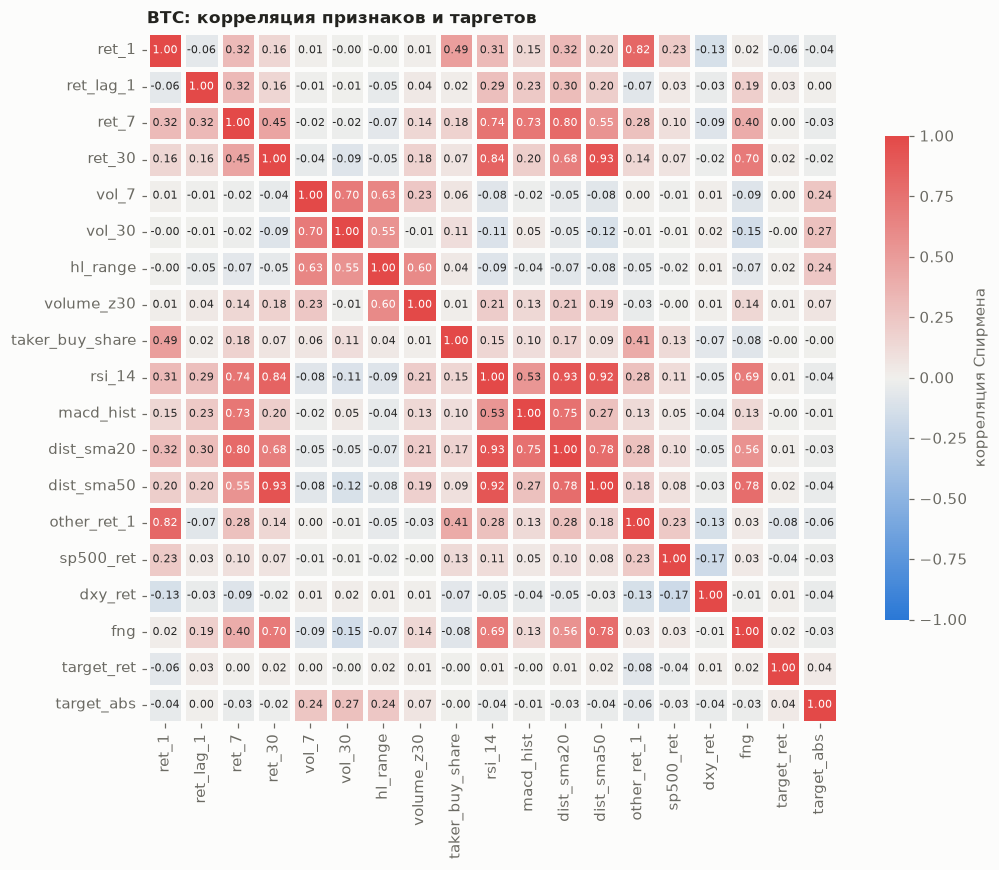

Пары признаков с |корреляцией Спирмена| > 0.7:


corr
ret_30     dist_sma50  0.9314
rsi_14     dist_sma20  0.9258
           dist_sma50  0.9157
ret_30     rsi_14      0.8360
ret_1      other_ret_1 0.8188
ret_7      dist_sma20  0.8043
dist_sma50 fng         0.7787
dist_sma20 dist_sma50  0.7763
macd_hist  dist_sma20  0.7509
ret_7      rsi_14      0.7364
           macd_hist   0.7265
ret_30     fng         0.7017
vol_7      vol_30      0.7001

In [17]:
corr = datasets["BTC"][FEATURES + ["target_ret", "target_abs"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap=DIVERGING, center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=2, linecolor=SURFACE, square=True, cbar_kws={"shrink": 0.7, "label": "корреляция Спирмена"}, ax=ax)
ax.set_title("BTC: корреляция признаков и таргетов")
plt.tight_layout()
plt.show()

pairs = corr.loc[FEATURES, FEATURES].where(np.triu(np.ones(len(FEATURES), dtype=bool), 1)).stack()
print("Пары признаков с |корреляцией Спирмена| > 0.7:")
display(pairs[pairs.abs() > 0.7].sort_values(key=abs, ascending=False).to_frame("corr"))

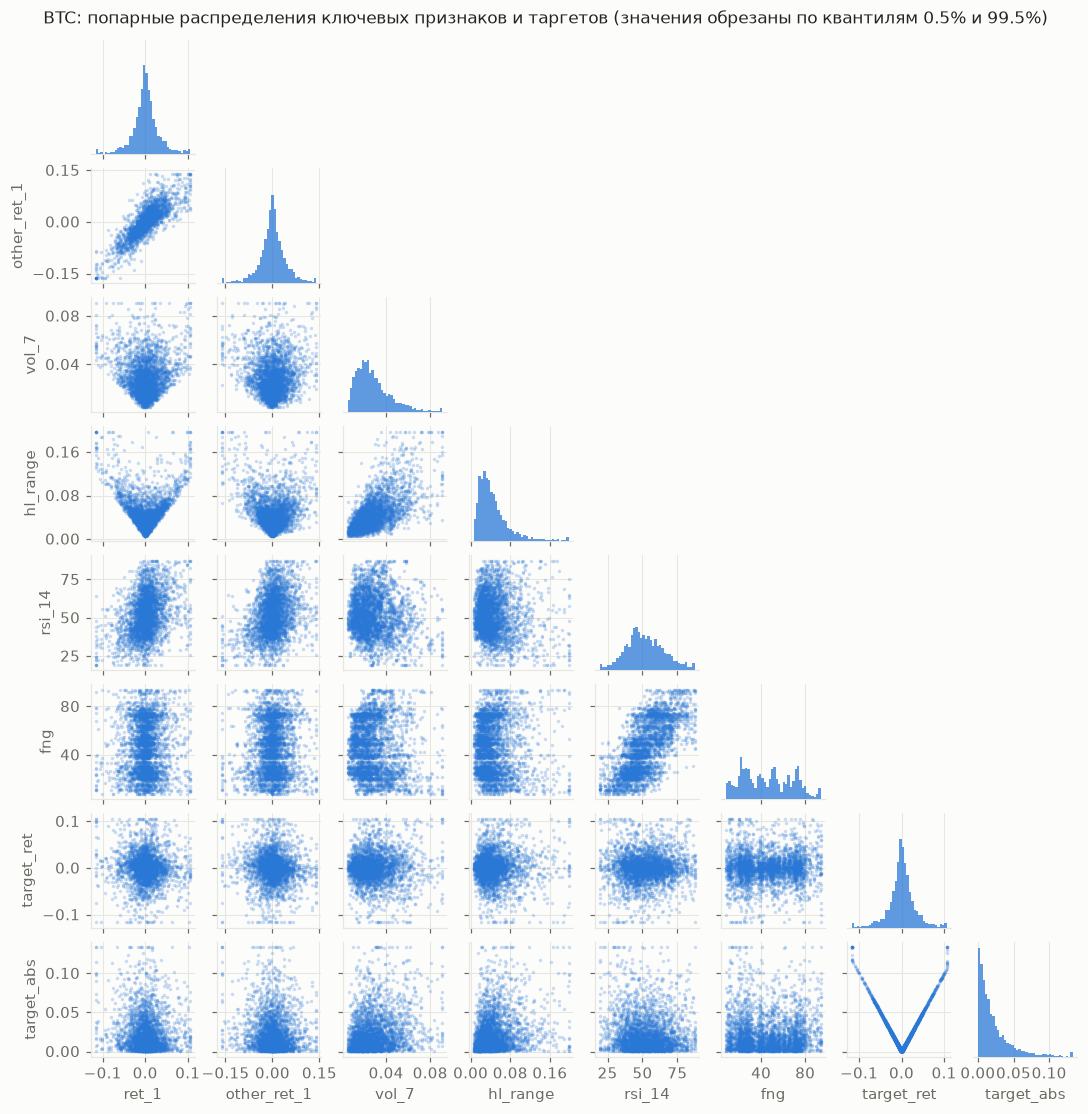

In [18]:
pair_columns = ["ret_1", "other_ret_1", "vol_7", "hl_range", "rsi_14", "fng", "target_ret", "target_abs"]
view = datasets["BTC"][pair_columns].copy()
view = view.clip(view.quantile(0.005), view.quantile(0.995), axis=1)
grid = sns.pairplot(view, corner=True, height=1.25, plot_kws={"s": 5, "alpha": 0.25, "color": BLUE, "linewidth": 0},
                    diag_kws={"color": BLUE, "bins": 40, "linewidth": 0})
for ax in grid.axes.ravel():
    if ax is not None:
        ax.xaxis.set_major_locator(plt.MaxNLocator(3))
        ax.yaxis.set_major_locator(plt.MaxNLocator(3))
grid.figure.suptitle("BTC: попарные распределения ключевых признаков и таргетов (значения обрезаны по квантилям 0.5% и 99.5%)", y=1.01, fontsize=11)
plt.show()

BTC: следующий день по классу Fear & Greed


,дней,средняя_доходность_t1,стд_t1,средний_модуль_t1,доля_роста_t1
Extreme Fear,743,0.0005,0.0414,0.0260,0.5316
Fear,916,-0.0010,0.0310,0.0209,0.4749
Neutral,411,-0.0008,0.0247,0.0168,0.4842
Greed,850,0.0025,0.0282,0.0194,0.5271
Extreme Greed,282,0.0031,0.0410,0.0303,0.5390


BTC: следующий день по зоне RSI(14)


,дней,средняя_доходность_t1,стд_t1,средний_модуль_t1,доля_роста_t1
rsi_14,,,,,
<30,137,0.0024,0.0516,0.0356,0.5474
30–50,1399,-0.0009,0.0343,0.0218,0.5061
50–70,1337,0.0014,0.0295,0.0203,0.5079
>70,329,0.0038,0.0337,0.0240,0.5076


BTC: следующий день после экстремального дня


,дней,средняя_доходность_t1,стд_t1,средний_модуль_t1,доля_роста_t1
ret_1,,,,,
падение > 5%,167,0.0066,0.0466,0.0324,0.5629
в пределах ±5%,2866,0.0005,0.0320,0.0210,0.5077
рост > 5%,169,-0.0016,0.0385,0.0279,0.4734


... (2 outputs left out)

ETH: следующий день по зоне RSI(14)


,дней,средняя_доходность_t1,стд_t1,средний_модуль_t1,доля_роста_t1
rsi_14,,,,,
<30,153,-0.0048,0.0632,0.0465,0.5033
30–50,1471,-0.0014,0.0440,0.0286,0.5051
50–70,1290,0.0021,0.0404,0.0282,0.5132
>70,288,0.0029,0.0480,0.0331,0.5243


ETH: следующий день после экстремального дня


,дней,средняя_доходность_t1,стд_t1,средний_модуль_t1,доля_роста_t1
ret_1,,,,,
падение > 5%,272,0.0057,0.0575,0.0423,0.5735
в пределах ±5%,2633,0.0001,0.0420,0.0279,0.5112
рост > 5%,297,-0.0034,0.0477,0.0339,0.4411


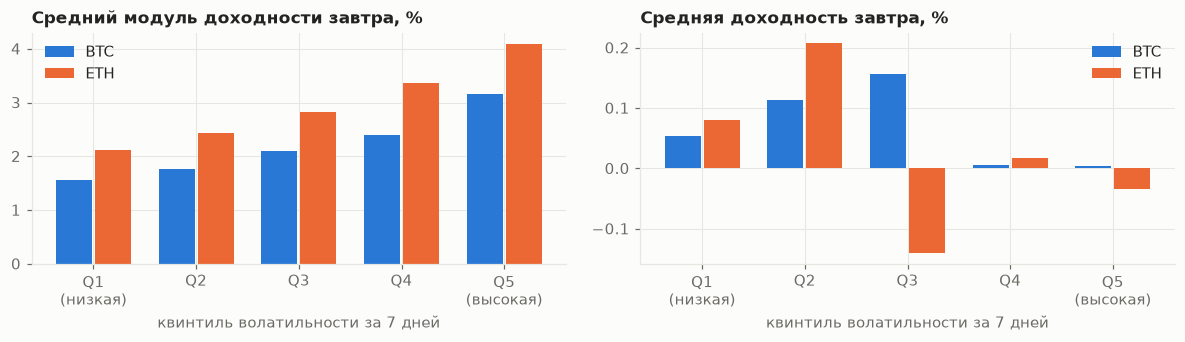

In [19]:
def pivot(data, groups):
    return data.groupby(groups, observed=True).agg(
        дней=("target_ret", "size"), средняя_доходность_t1=("target_ret", "mean"),
        стд_t1=("target_ret", "std"), средний_модуль_t1=("target_abs", "mean"), доля_роста_t1=("target_up", "mean"))


fng_labels = ["Extreme Fear", "Fear", "Neutral", "Greed", "Extreme Greed"]
for name, data in datasets.items():
    classes = fng["fng_class"].reindex(data.index).ffill(limit=3)
    print(f"{name}: следующий день по классу Fear & Greed")
    display(pivot(data, pd.Categorical(classes, categories=fng_labels, ordered=True)))
    print(f"{name}: следующий день по зоне RSI(14)")
    display(pivot(data, pd.cut(data["rsi_14"], [0, 30, 50, 70, 100], labels=["<30", "30–50", "50–70", ">70"])))
    print(f"{name}: следующий день после экстремального дня")
    display(pivot(data, pd.cut(data["ret_1"], [-np.inf, -0.05, 0.05, np.inf], labels=["падение > 5%", "в пределах ±5%", "рост > 5%"])))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
width = 0.38
for offset, (name, data) in zip([-width / 2, width / 2], datasets.items()):
    quintile = pd.qcut(data["vol_7"], 5, labels=False)
    axes[0].bar(np.arange(5) + offset, data.groupby(quintile)["target_abs"].mean() * 100, width - 0.03, color=ASSET_COLORS[name], label=name)
    axes[1].bar(np.arange(5) + offset, data.groupby(quintile)["target_ret"].mean() * 100, width - 0.03, color=ASSET_COLORS[name], label=name)
axes[0].set_title("Средний модуль доходности завтра, %")
axes[1].set_title("Средняя доходность завтра, %")
for ax in axes:
    ax.set_xticks(range(5), ["Q1\n(низкая)", "Q2", "Q3", "Q4", "Q5\n(высокая)"])
    ax.set_xlabel("квинтиль волатильности за 7 дней")
    ax.legend()
plt.tight_layout()
plt.show()

**Связь с доходностью следующего дня очень слаба.** Из 34 проверок (17 признаков на 2 актива) после поправки Бенджамини—Хохберга значимы только три, и все они слабые (корреляция Пирсона по модулю около 0.08 и ниже):

| Актив | Признак | Корреляция | p (BH) | 2018–2021 | 2022–2026 |
|---|---|---|---|---|---|
| BTC | `other_ret_1` (доходность ETH сегодня) | −0.080 | 0.030 | −0.108 | −0.030 |
| ETH | `ret_1` (своя доходность сегодня) | −0.074 | 0.046 | −0.106 | −0.018 |
| ETH | `ret_lag_1` (своя доходность вчера) | +0.060 | 0.046 | +0.087 | +0.013 |

Все три эффекта сильно ослабли после 2022 года. Для `ret_lag_1` корреляция Спирмена равна всего 0.014, то есть связь держится на выбросах. Хотя S&P 500 даёт одну из самых заметных связей в 2022–2026 годах (−0.064 для BTC), после поправки на множественные проверки она незначима (p = 0.084). То же относится к Fear & Greed (0.037 и 0.049; p = 0.15 и 0.07).

**Сводные таблицы.**

- *Fear & Greed.* Средняя доходность следующего дня выше в зонах Greed и Extreme Greed (BTC +0.25% и +0.31%), а в зонах Fear и Neutral отрицательна (−0.10% и −0.08%). Но эти средние невелики по сравнению с разбросом, а значимость на дневном уровне не подтверждается. Намного устойчивее другой эффект: модуль доходности в крайних зонах выше (BTC 2.6% и 3.0% против 1.7% в Neutral, ETH 3.6% и 3.7% против 2.2%).
- *RSI.* Классическая интерпретация не подтверждается. При RSI > 70 следующий день в среднем положительный у обоих активов (BTC +0.38%, ETH +0.29%), при RSI < 30 результат различается (BTC +0.24%, ETH −0.48%).
- *После экстремального дня* заметен слабый разворот: после падения более чем на 5% доля роста 56.3% для BTC (167 дней) и 57.4% для ETH (272 дня), после роста более чем на 5% — 47.3% (169 дней) и 44.1% (297 дней). Выборки невелики, это описательный результат, он будет проверен walk-forward валидацией.

**Связь с величиной движения заметна и устойчива.** Корреляция Спирмена с модулем доходности следующего дня: `vol_30` 0.27 и `vol_7` 0.24 для BTC, `vol_7` 0.25 и `hl_range` 0.22 для ETH (t-статистики Ньюи—Уэста от 6.6 до 11.5, значимо после поправки). `volume_z30` тоже значим (0.07–0.09). Средний модуль доходности от нижнего к верхнему квинтилю недельной волатильности растёт примерно вдвое у обоих активов, а средняя доходность закономерно не меняется.

**Мультиколлинеарность.** Признаки импульса почти дублируют друг друга: `ret_30` и `dist_sma50` (0.93), `rsi_14` и `dist_sma20` (0.93), `rsi_14` и `dist_sma50` (0.92), `ret_30` и `rsi_14` (0.84). Fear & Greed тоже связан с импульсом (0.78 с `dist_sma50`, 0.70 с `ret_30`), то есть во многом отражает прошлую динамику цены. Из каждой группы в линейные модели войдёт один-два представителя, а бустинг будет проверяться на разных наборах.

## 8. Черновой выбор метрик и опорные значения

Отложенный период — с 1 января 2024 года, обучающая часть (для масштаба MASE и исторического среднего) — всё, что раньше. Здесь мы не обучаем модели, а фиксируем значения простейших правил, которые модели на ЧП 3 должны будут превзойти.

In [20]:
HOLDOUT = "2024-01-01"


def reference_metrics(df, name):
    close, ret = df["close"], np.log(df["close"]).diff().dropna()
    y_price = close.loc[HOLDOUT:]
    naive_price = close.shift().loc[HOLDOUT:]
    train_ret = ret.loc[:pd.Timestamp(HOLDOUT) - pd.Timedelta(days=1)]
    drift = ret.expanding().mean().shift().loc[HOLDOUT:]
    actual = ret.loc[HOLDOUT:]
    scale = (close.loc[:pd.Timestamp(HOLDOUT) - pd.Timedelta(days=1)].diff().abs()).mean()
    ret_scale = train_ret.abs().mean()
    train_up = (train_ret > 0).mean()
    up_rate = (actual > 0).mean()
    return {
        "актив": name, "дней в отложенном периоде": len(actual),
        "MAE цены, наивный": (y_price - naive_price).abs().mean(),
        "RMSE цены, наивный": np.sqrt(((y_price - naive_price) ** 2).mean()),
        "MAPE цены, наивный, %": ((y_price - naive_price).abs() / y_price).mean() * 100,
        "MASE цены, наивный": (y_price - naive_price).abs().mean() / scale,
        "R² уровня цены, наивный": 1 - ((y_price - naive_price) ** 2).sum() / ((y_price - y_price.mean()) ** 2).sum(),
        "MAE доходности, нулевой прогноз": actual.abs().mean(),
        "MAE доходности, историческое среднее": (actual - drift).abs().mean(),
        "RMSE доходности, нулевой прогноз": np.sqrt((actual ** 2).mean()),
        "R² доходности, нулевой прогноз": 1 - (actual ** 2).sum() / ((actual - actual.mean()) ** 2).sum(),
        "MASE доходности, нулевой прогноз": actual.abs().mean() / ret_scale,
        "доля роста в train": train_up, "доля роста в отложенном периоде": up_rate,
        "accuracy, всегда рост": up_rate,
    }


pd.DataFrame([reference_metrics(df, name) for name, df in ASSETS.items()]).set_index("актив").T

актив,BTC,ETH
дней в отложенном периоде,"1,044.0000","1,044.0000"
"MAE цены, наивный","1,354.1374",68.5766
"RMSE цены, наивный","1,907.9340",100.9822
"MAPE цены, наивный, %",1.7222,2.4255
"MASE цены, наивный",2.5595,1.7637
"R² уровня цены, наивный",0.9907,0.9812
"MAE доходности, нулевой прогноз",0.0172,0.0243
"MAE доходности, историческое среднее",0.0173,0.0243
"RMSE доходности, нулевой прогноз",0.0244,0.0350
"R² доходности, нулевой прогноз",-0.0005,-0.0000


**Что показывают опорные значения.**

- **Уровень цены вводит в заблуждение.** Наивный прогноз «завтра как сегодня» даёт R² цены 0.99 для BTC и 0.98 для ETH, MAPE 1.72% и 2.43%, не имея предсказательной силы. Поэтому R² уровня цены использоваться не будет.
- **На доходностях наивный прогноз равносилен нулевому:** MAE 0.0172 (BTC) и 0.0243 (ETH), RMSE 0.0244 и 0.0350. Историческое среднее не лучше: MAE 0.0173 и 0.0243. Это значения, которые должны превзойти модели на ЧП 3.
- **MASE требует осторожности.** Если масштаб считать на обучающей части, значения плохо сравнимы: 2.56 и 1.76 на цене (цены на отложенном периоде намного выше, чем на обучении) и 0.67 и 0.73 на доходностях (отложенный период спокойнее). Поэтому для сравнения моделей лучше считать отношение MAE модели к MAE наивного прогноза на тех же фолдах.
- **Направление.** Стратегия «всегда рост» даёт accuracy 50.6% (BTC) и 51.2% (ETH). Классы почти сбалансированы, но модель с accuracy 51–52% пока ничего не доказывает.

**Черновой выбор метрик.**

| Задача | Метрика | Почему |
|---|---|---|
| Регрессия доходности (основная) | MAE и отношение MAE к наивному прогнозу | устойчивость к выбросам, прямое сравнение с бейзлайном |
| Дополнительно | RMSE, MAPE цены | чувствительность к крупным ошибкам и понятная интерпретация |
| Направление | ROC-AUC, accuracy относительно базовой | не зависит от порога, контроль базовой доли класса |
| Опционально | бэктест с комиссиями, QLIKE для волатильности | экономический смысл, стандартная функция потерь для волатильности |

Окончательный выбор метрики будет сделан на ЧП 3.

## 9. Итоговые выводы и их использование

**Качество данных**

1. Котировки Binance полны и логически корректны. Пропуски есть только во внешних рядах и означают закрытие рынка, что подтверждено сверкой с календарём NYSE. Обработка: заполнение последним известным значением для S&P 500 и DXY, ограниченное заполнение для Fear & Greed, рабочая выборка с 1 февраля 2018 года.
2. Выбросы — реальные события, они сохраняются и обрабатываются внутри обучающих окон, а не удаляются.
3. Объём BTC содержит структурный сдвиг из-за периода нулевой комиссии, поэтому будет использоваться только в относительной форме и с флагом периода.

**Свойства рядов**

4. Цены нестационарны, лог-доходности стационарны: целевой переменной будет лог-доходность.
5. Распределение доходностей имеет очень тяжёлые хвосты (степени свободы около 3), поэтому основная метрика — MAE, а не RMSE.
6. Рынок менял режимы: волатильность BTC упала примерно вдвое по сравнению с 2020–2021 годами, эффекты краткосрочного разворота почти исчезли после 2022 года. Отсюда требование walk-forward валидации и внимание к качеству на последних годах.
7. Устойчивой сезонности в средней доходности нет. Сезонность есть у волатильности (выходные спокойнее).
8. Волатильность сильно кластеризуется и предсказуема намного лучше доходности.
9. BTC и ETH сильно связаны в рамках одного дня, но лидера нет и коинтеграция не подтверждается.

**Главный вывод.** На дневном горизонте доходность предсказывается очень слабо: из 34 проверок значимы только три связи с корреляцией по модулю около 0.08 и ниже, и они ослабли в последние годы. Ожидать большого прироста качества в прогнозе доходности и направления не следует. Заметный сигнал есть в прогнозе величины движения.

**Как это будет использовано на следующих этапах**

- **ЧП 3.** Бейзлайны: наивный прогноз, историческое среднее, ARIMA на лог-цене. Экспоненциальное сглаживание будет включено как обязательный по плану бейзлайн, хотя устойчивого тренда в доходности EDA не показывает. Валидация walk-forward с расширяющимся окном, все преобразования обучаются только на обучающем окне. Признаки: лаги доходности, волатильность разных окон, `hl_range`, `volume_z30`, флаг нулевой комиссии, день недели и флаг выходного, доходности другого актива, S&P 500 и DXY, Fear & Greed. Из групп коррелирующих признаков отбираются представители. Отдельно стоит добавить прогноз величины движения как дополнительную задачу, поскольку в ней сигнал наиболее выражен.
- **ЧП 5.** Гипотеза о пользе новостей будет проверяться с учётом того, что Fear & Greed уже во многом отражает прошлую динамику цены: новостные признаки должны давать информацию сверх импульса. Сравнение «только ряды» и «ряды + новости» должно идти на одних и тех же фолдах.
- **ЧП 7.** Анализ ошибок по режимам: высокая и низкая волатильность, кризисные дни, период 2022–2026 годов.

**Ограничения анализа.** Использована одна биржа и два крупнейших актива, поэтому результаты могут не переноситься на менее ликвидные монеты. Корреляции улавливают в основном линейные и монотонные связи, нелинейные эффекты будут проверяться моделями. Все эффекты оценены на исторической выборке, включая период, используемый как отложенный: окончательная оценка возможна только при walk-forward проверке. Результаты не являются инвестиционной рекомендацией.